# 01. Khám phá & Phân tích Dữ liệu Lệch Cực đoan (EDA Overview)
### Đề tài 13: Credit Card Fraud Detection (Unsupervised Anomaly Detection)
* **Học phần:** Khai phá Dữ liệu (Data Mining) — PTIT
* **Sinh viên thực hiện:** 
  * Nguyễn Văn Hiển Vinh (B23DCVT461) — *Leader / Data & Preprocessing Lead*
  * Nguyễn Minh Hoàng (B23DCVT173) — *Modeling & Evaluation Lead*
* **Kế hoạch thực hiện:** Phase 1 (Ngày 2 – Ngày 3) theo Kế hoạch V2.1
* **Mục tiêu chính:**
  1. Đọc và kiểm định tính toàn vẹn của dataset thô (284.807 dòng, 31 cột, 0 missing values).
  2. Phân tích chi tiết 1.081 dòng trùng lặp (duplicates) và làm rõ lý do nghiệp vụ bảo lưu 19 mẫu Fraud.
  3. Phân tích độ mất cân bằng lớp cực đoan (99.827% Normal vs 0.173% Fraud) và giải thích tại sao cấm dùng Accuracy.
  4. Khảo sát đặc tính phân phối của 2 biến chưa chuẩn hóa: `Amount` (lệch phải cực lớn) và `Time` (chu kỳ 48h).
  5. Phân tích tương quan của 28 đặc trưng PCA `V1`–`V28` với nhãn `Class`, trực quan hóa các đặc trưng có khả năng phân tách gian lận cao nhất (V14, V12, V10, V17, V11, V4).
  6. Xuất 4 bộ biểu đồ chuẩn hóa lưu vào thư mục `reports/figures/` phục vụ báo cáo kỹ thuật.


In [1]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG & NẠP THƯ VIỆN
# ==============================================================================
# Giảng viên hỏi: Các thư viện này dùng làm gì?
# Bạn trả lời:
# - pandas & numpy: Thao tác bảng dữ liệu và tính toán đại số ma trận.
# - matplotlib & seaborn: Vẽ biểu đồ trực quan hóa phân phối và tương quan.
# - scipy.stats: Đo độ bất đối xứng (skewness) và độ nhọn (kurtosis) của biến Amount.
# - src.config: Nạp các tham số cố định (seed 42, đường dẫn lưu ảnh) đảm bảo tính tái lập 100%.

import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Thiết lập đường dẫn gốc project
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from src.config import RAW_DATA_PATH, FIGURES_DIR, RANDOM_STATE
from src.data_loader import load_raw_data

# Thiết lập cấu hình đồ họa thẩm mỹ chuẩn IEEE
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#333333'
plt.rcParams['axes.linewidth'] = 0.8
sns.set_theme(style="whitegrid", palette="muted")
np.random.seed(RANDOM_STATE)

# Đảm bảo thư mục lưu biểu đồ tồn tại
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"[OK] Môi trường sẵn sàng. Seed={RANDOM_STATE}. Lưu biểu đồ tại: {FIGURES_DIR}")


[OK] Môi trường sẵn sàng. Seed=42. Lưu biểu đồ tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures


---
## 1. Nạp Dữ liệu & Kiểm định Kích thước (Data Loading & Integrity Verification)
* Dataset gốc: `data/raw/creditcard.csv` tải từ Kaggle.
* Chúng ta sử dụng hàm `load_raw_data()` từ module `src.data_loader` đã được tích hợp kiểm tra toàn vẹn (`assert`).


In [2]:
# Nạp dataset thô thông qua hàm chuẩn hóa đã viết sẵn trong src/data_loader.py
df = load_raw_data(RAW_DATA_PATH)

print(f"-> Kích thước bảng dữ liệu (Shape): {df.shape[0]:,} dòng x {df.shape[1]} cột")
print(f"-> Dung lượng chiếm trong RAM: {df.memory_usage().sum() / (1024**2):.2f} MB")
print("\n-> Xem trước 5 dòng đầu tiên:")
df.head()


-> Kích thước bảng dữ liệu (Shape): 284,807 dòng x 31 cột
-> Dung lượng chiếm trong RAM: 67.36 MB

-> Xem trước 5 dòng đầu tiên:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


---
## 2. Kiểm tra Giá trị Khuyết thiếu (Missing Values) & Dòng Trùng lặp (Duplicates)
### Vấn đề kỹ thuật cốt lõi:
1. **Giá trị khuyết thiếu (Null/NaN):** Nếu có ô trống, ta phải xử lý bằng cách điền (imputation) hoặc loại bỏ.
2. **Dòng trùng lặp (Duplicate rows):** Trong xử lý dữ liệu thông thường, ta hay gọi lệnh `drop_duplicates()`. Nhưng với bài toán gian lận cực đoan, **hành động này có an toàn không?**


In [3]:
# 1. Kiểm tra ô khuyết thiếu (Missing Values)
total_missing = df.isnull().sum().sum()
print("=" * 60)
print(f"[KIỂM TOÁN DỮ LIỆU 1] Tổng số ô bị khuyết thiếu (Missing/NaN): {total_missing}")
if total_missing == 0:
    print("=> KẾT LUẬN: Dữ liệu hoàn toàn sạch, không cần thực hiện bước Imputation!")
print("=" * 60)

# 2. Kiểm tra các dòng trùng lặp (Duplicate Rows)
num_duplicates = df.duplicated().sum()
print(f"\n[KIỂM TOÁN DỮ LIỆU 2] Tổng số dòng trùng lặp hoàn toàn: {num_duplicates:,} dòng")

# Phân tích xem 1.081 dòng trùng lặp này thuộc lớp nào?
dup_by_class = df[df.duplicated(keep=False)]['Class'].value_counts()
dup_first_only = df[df.duplicated(keep='first')]['Class'].value_counts()

print("-> Phân bố nhãn trong 1.081 dòng trùng (nếu drop_duplicates sẽ bị xóa):")
print(f"   + Class 0 (Normal): {dup_first_only.get(0, 0):,} dòng")
print(f"   + Class 1 (Fraud) : {dup_first_only.get(1, 0):,} dòng  <-- CỰC KỲ NGUY HIỂM!")

pct_fraud_lost = (dup_first_only.get(1, 0) / (df['Class'] == 1).sum()) * 100
print(f"\n=> CẢNH BÁO QUAN TRỌNG: Nếu gọi df.drop_duplicates(), ta sẽ xóa mất {dup_first_only.get(1, 0)} mẫu gian lận,")
print(f"   tương đương làm mất {pct_fraud_lost:.2f}% tổng số lượng mẫu gian lận hiếm hoi trong toàn bộ bài toán!")
print("=> QUYẾT ĐỊNH KHOA HỌC: BẢO LƯU NGUYÊN VẸN 1.081 DÒNG TRÙNG LẶP. Không xóa bất kỳ dòng nào.")


[KIỂM TOÁN DỮ LIỆU 1] Tổng số ô bị khuyết thiếu (Missing/NaN): 0
=> KẾT LUẬN: Dữ liệu hoàn toàn sạch, không cần thực hiện bước Imputation!



[KIỂM TOÁN DỮ LIỆU 2] Tổng số dòng trùng lặp hoàn toàn: 1,081 dòng


-> Phân bố nhãn trong 1.081 dòng trùng (nếu drop_duplicates sẽ bị xóa):
   + Class 0 (Normal): 1,062 dòng
   + Class 1 (Fraud) : 19 dòng  <-- CỰC KỲ NGUY HIỂM!

=> CẢNH BÁO QUAN TRỌNG: Nếu gọi df.drop_duplicates(), ta sẽ xóa mất 19 mẫu gian lận,
   tương đương làm mất 3.86% tổng số lượng mẫu gian lận hiếm hoi trong toàn bộ bài toán!
=> QUYẾT ĐỊNH KHOA HỌC: BẢO LƯU NGUYÊN VẸN 1.081 DÒNG TRÙNG LẶP. Không xóa bất kỳ dòng nào.


---
## 3. Phân tích Độ Mất Cân Bằng Lớp Cực Đoan (Severe Class Imbalance)
* Tổng số giao dịch: **284.807**
* Giao dịch Bình thường (Class 0): **284.315** ($99,827\%$)
* Giao dịch Gian lận (Class 1): **492** ($0,173\%$)

> [!WARNING]
> **Cấm dùng Accuracy (Độ chính xác toàn thể):**
> Nếu một mô hình dự đoán tất cả giao dịch đều là "Bình thường", nó đạt ngay Accuracy = **$99,827\%$**. Nhưng mô hình đó hoàn toàn vô dụng vì bỏ lọt $100\%$ các vụ trộm tiền của ngân hàng!
> Do đó, ta bắt buộc phải sử dụng **Precision, Recall, F1-Score và AUPRC (Average Precision)** làm thước đo trung tâm.


Class 0 (Normal): 284,315 giao dịch (99.8273%)
Class 1 (Fraud) : 492 giao dịch (0.1727%)
Tỷ lệ mất cân bằng (Imbalance Ratio): 1 : 577


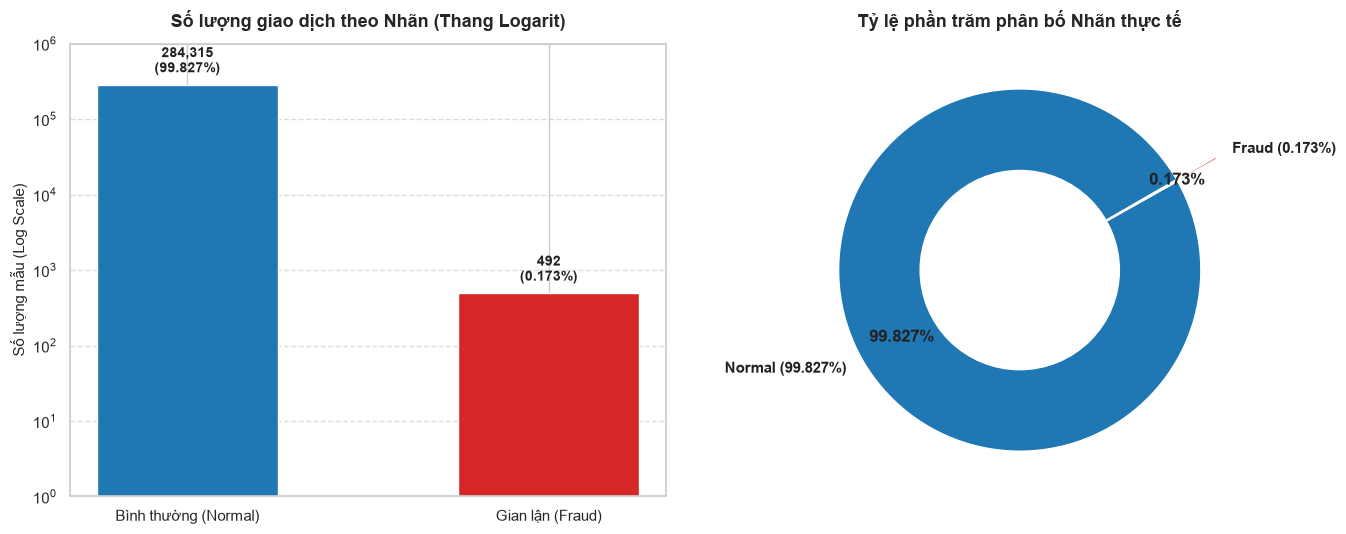

[ĐÃ XUẤT ẢNH] Lưu biểu đồ 1 thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\01_class_distribution.png


In [4]:
# Tính toán số lượng và tỷ lệ phần trăm
class_counts = df['Class'].value_counts()
n_normal = class_counts[0]
n_fraud = class_counts[1]
pct_normal = (n_normal / len(df)) * 100
pct_fraud = (n_fraud / len(df)) * 100

print(f"Class 0 (Normal): {n_normal:,} giao dịch ({pct_normal:.4f}%)")
print(f"Class 1 (Fraud) : {n_fraud:,} giao dịch ({pct_fraud:.4f}%)")
print(f"Tỷ lệ mất cân bằng (Imbalance Ratio): 1 : {int(n_normal / n_fraud)}")

# ==============================================================================
# VẼ BIỂU ĐỒ 1: PHÂN BỐ LỆCH LỚP (BAR CHART + DONUT CHART)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Bar Chart (Sử dụng thang đo Log để nhìn thấy cột Fraud)
colors = ['#1f77b4', '#d62728']
bars = axes[0].bar(['Bình thường (Normal)', 'Gian lận (Fraud)'], [n_normal, n_fraud], color=colors, width=0.5)
axes[0].set_yscale('log')
axes[0].set_title('Số lượng giao dịch theo Nhãn (Thang Logarit)', fontsize=13, fontweight='bold', pad=12)
axes[0].set_ylabel('Số lượng mẫu (Log Scale)', fontsize=11)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Ghi chú con số cụ thể trên đầu mỗi cột
for bar, count, pct in zip(bars, [n_normal, n_fraud], [pct_normal, pct_fraud]):
    axes[0].text(
        bar.get_x() + bar.get_width()/2., bar.get_height() * 1.3,
        f"{count:,}\n({pct:.3f}%)",
        ha='center', va='bottom', fontsize=10, fontweight='bold', color='#222222'
    )
axes[0].set_ylim(1, 10**6)

# 2. Donut Chart thể hiện mức độ độc chiếm của Normal
wedges, texts, autotexts = axes[1].pie(
    [n_normal, n_fraud],
    labels=['Normal (99.827%)', 'Fraud (0.173%)'],
    colors=colors,
    explode=(0, 0.25),
    autopct='%1.3f%%',
    pctdistance=0.75,
    startangle=30,
    textprops=dict(color="#222222", fontweight='bold')
)
# Vẽ hình tròn trắng ở giữa tạo hiệu ứng Donut
centre_circle = plt.Circle((0, 0), 0.55, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title('Tỷ lệ phần trăm phân bố Nhãn thực tế', fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
fig1_path = FIGURES_DIR / "01_class_distribution.png"
plt.savefig(fig1_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[ĐÃ XUẤT ẢNH] Lưu biểu đồ 1 thành công tại: {fig1_path}")


---
## 4. Phân tích Các Đặc trưng Chưa Chuẩn hóa: `Amount` và `Time`
* **Cột `Amount` (Số tiền quẹt thẻ):** Có phân phối lệch phải (Right-skewed) cực kỳ lớn với các khoản chi tiêu khổng lồ.
* **Cột `Time` (Thời gian):** Đo bằng số giây tính từ giao dịch đầu tiên trong tập dữ liệu (khoảng 48 giờ liên tục).


In [5]:
# Thống kê mô tả số học của Amount và Time theo từng Class
stats_amount = df.groupby('Class')['Amount'].describe().T
print("=" * 70)
print("BẢNG THỐNG KÊ MÔ TẢ ĐẶC TRƯNG AMOUNT (SỐ TIỀN GIAO DỊCH):")
print(stats_amount.round(2))
print("=" * 70)

# Đo độ lệch (Skewness) và độ nhọn (Kurtosis) của Amount
skew_val = df['Amount'].skew()
kurt_val = df['Amount'].kurtosis()
print(f"-> Độ bất đối xứng (Skewness) của Amount: {skew_val:.2f} (Lệch phải cực kỳ mạnh > 0)")
print(f"-> Độ nhọn (Kurtosis) của Amount: {kurt_val:.2f} (Phân phối có đuôi rất dày / Heavy-tailed)")

# So sánh trung vị (Median) và trung bình (Mean) giữa Normal và Fraud
med_normal = df[df['Class'] == 0]['Amount'].median()
med_fraud = df[df['Class'] == 1]['Amount'].median()
mean_normal = df[df['Class'] == 0]['Amount'].mean()
mean_fraud = df[df['Class'] == 1]['Amount'].mean()

print(f"\n-> Giao dịch Normal: Trung vị = {med_normal:.2f} USD, Trung bình = {mean_normal:.2f} USD")
print(f"-> Giao dịch Fraud : Trung vị = {med_fraud:.2f} USD, Trung bình = {mean_fraud:.2f} USD")
print(f"=> NHẬN XÉT: Trung vị tiền gian lận ({med_fraud} USD) thấp hơn nhiều so với giao dịch bình thường ({med_normal} USD).")
print("   Kẻ gian thường thử quẹt thẻ các khoản tiền nhỏ để tránh kích hoạt hệ thống cảnh báo SMS!")


BẢNG THỐNG KÊ MÔ TẢ ĐẶC TRƯNG AMOUNT (SỐ TIỀN GIAO DỊCH):
Class          0        1
count  284315.00   492.00
mean       88.29   122.21
std       250.11   256.68
min         0.00     0.00
25%         5.65     1.00
50%        22.00     9.25
75%        77.05   105.89
max     25691.16  2125.87
-> Độ bất đối xứng (Skewness) của Amount: 16.98 (Lệch phải cực kỳ mạnh > 0)
-> Độ nhọn (Kurtosis) của Amount: 845.09 (Phân phối có đuôi rất dày / Heavy-tailed)

-> Giao dịch Normal: Trung vị = 22.00 USD, Trung bình = 88.29 USD
-> Giao dịch Fraud : Trung vị = 9.25 USD, Trung bình = 122.21 USD
=> NHẬN XÉT: Trung vị tiền gian lận (9.25 USD) thấp hơn nhiều so với giao dịch bình thường (22.0 USD).
   Kẻ gian thường thử quẹt thẻ các khoản tiền nhỏ để tránh kích hoạt hệ thống cảnh báo SMS!


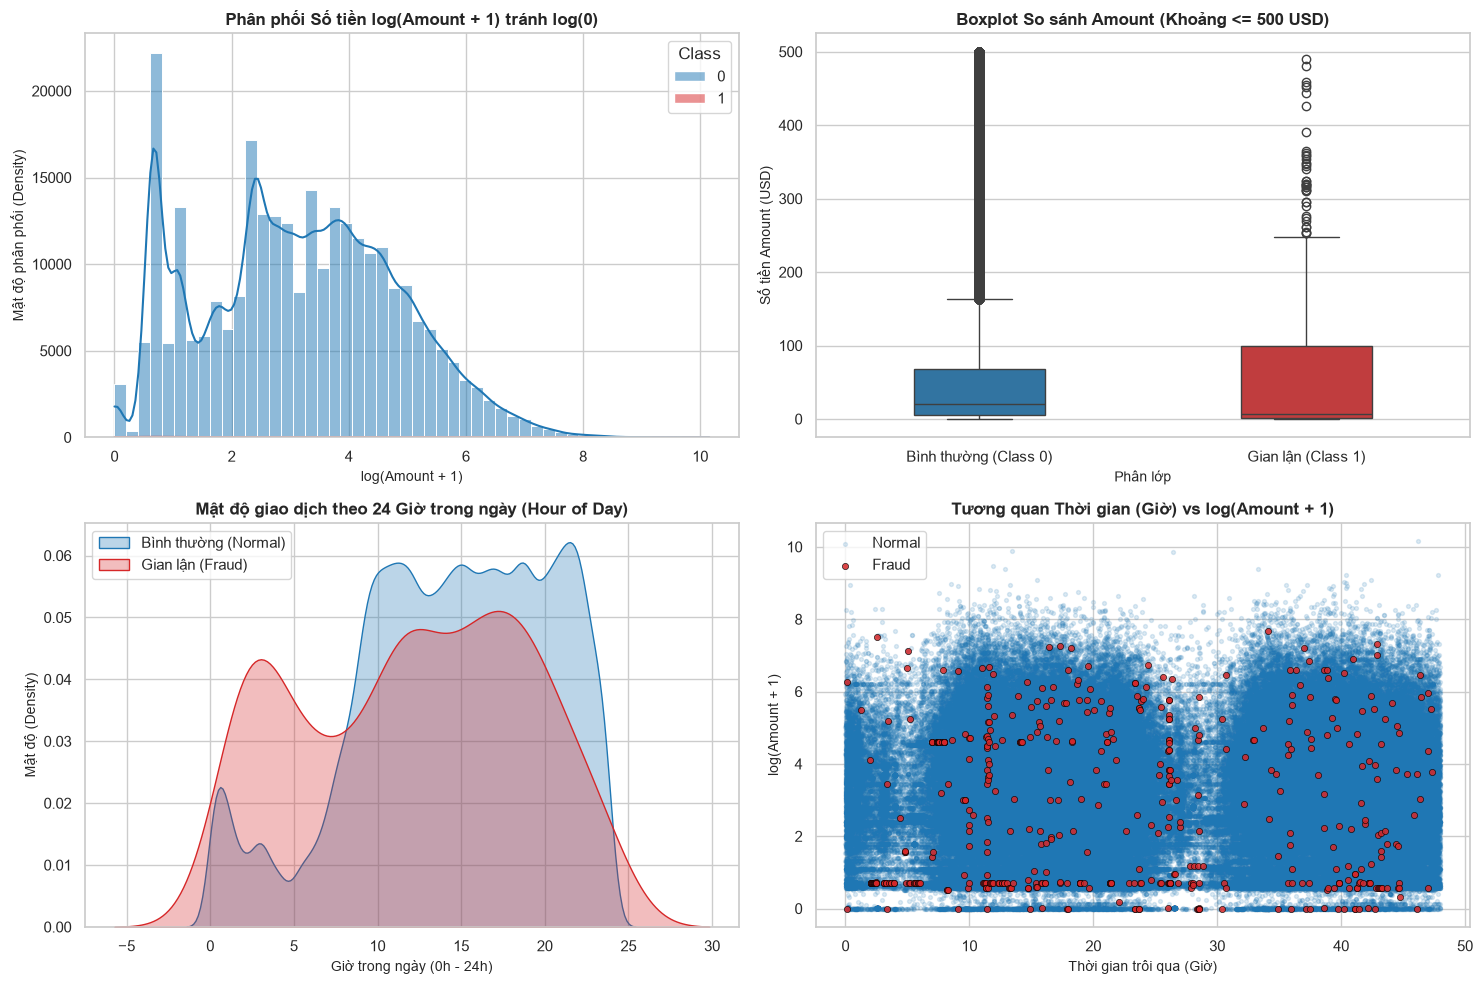

[ĐÃ XUẤT ẢNH] Lưu biểu đồ 2 thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\02_amount_time_distribution.png


In [6]:
# ==============================================================================
# VẼ BIỂU ĐỒ 2: PHÂN PHỐI AMOUNT VÀ TIME (4 SUBPLOTS)
# ==============================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Subplot 1: Phân phối Amount dạng Log1p (tránh log(0) do có 1.825 giao dịch 0 USD)
df['log_amount'] = np.log1p(df['Amount'])
sns.histplot(
    data=df, x='log_amount', hue='Class', bins=50,
    palette=['#1f77b4', '#d62728'], kde=True, ax=axes[0, 0], common_norm=False
)
axes[0, 0].set_title('Phân phối Số tiền log(Amount + 1) tránh log(0)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('log(Amount + 1)', fontsize=10)
axes[0, 0].set_ylabel('Mật độ phân phối (Density)', fontsize=10)

# Subplot 2: Boxplot so sánh Amount giữa 2 lớp (giới hạn hiển thị dưới 500 USD để nhìn rõ)
sns.boxplot(
    data=df[df['Amount'] <= 500], x='Class', y='Amount',
    palette=['#1f77b4', '#d62728'], ax=axes[0, 1], width=0.4
)
axes[0, 1].set_xticklabels(['Bình thường (Class 0)', 'Gian lận (Class 1)'])
axes[0, 1].set_title('Boxplot So sánh Amount (Khoảng <= 500 USD)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Phân lớp', fontsize=10)
axes[0, 1].set_ylabel('Số tiền Amount (USD)', fontsize=10)

# Subplot 3: Mật độ giao dịch theo thời gian trong 48 giờ (Time quy đổi ra giờ)
df['Hour'] = (df['Time'] / 3600) % 24
sns.kdeplot(
    data=df[df['Class'] == 0]['Hour'], label='Bình thường (Normal)',
    color='#1f77b4', fill=True, alpha=0.3, ax=axes[1, 0]
)
sns.kdeplot(
    data=df[df['Class'] == 1]['Hour'], label='Gian lận (Fraud)',
    color='#d62728', fill=True, alpha=0.3, ax=axes[1, 0]
)
axes[1, 0].set_title('Mật độ giao dịch theo 24 Giờ trong ngày (Hour of Day)', fontsize=12, fontweight='bold')
axes[1, 0].set_xlabel('Giờ trong ngày (0h - 24h)', fontsize=10)
axes[1, 0].set_ylabel('Mật độ (Density)', fontsize=10)
axes[1, 0].legend()

# Subplot 4: Biểu đồ phân tán Time vs log(Amount + 1)
axes[1, 1].scatter(
    df[df['Class'] == 0]['Time'] / 3600, df[df['Class'] == 0]['log_amount'],
    c='#1f77b4', alpha=0.15, s=8, label='Normal'
)
axes[1, 1].scatter(
    df[df['Class'] == 1]['Time'] / 3600, df[df['Class'] == 1]['log_amount'],
    c='#d62728', alpha=0.85, s=20, label='Fraud', edgecolors='black', linewidth=0.5
)
axes[1, 1].set_title('Tương quan Thời gian (Giờ) vs log(Amount + 1)', fontsize=12, fontweight='bold')
axes[1, 1].set_xlabel('Thời gian trôi qua (Giờ)', fontsize=10)
axes[1, 1].set_ylabel('log(Amount + 1)', fontsize=10)
axes[1, 1].legend()

plt.tight_layout()
fig2_path = FIGURES_DIR / "02_amount_time_distribution.png"
plt.savefig(fig2_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[ĐÃ XUẤT ẢNH] Lưu biểu đồ 2 thành công tại: {fig2_path}")


---
## 5. Phân tích Tương quan của 28 Đặc trưng PCA `V1`–`V28` với Nhãn `Class`
* 28 biến $V_1 \dots V_{28}$ là các thành phần chính trực giao được ngân hàng trích xuất bằng thuật toán PCA để bảo mật dữ liệu khách hàng.
* Mục tiêu: Tìm xem những biến nào có độ tương quan mạnh nhất (cả âm và dương) với nhãn `Class` để hiểu cơ sở phân tách bất thường.


Số đặc trưng gốc được tính tương quan: 30 (đã loại Class, Hour, log_amount)
TOP 5 ĐẶC TRƯNG CÓ TƯƠNG QUAN ÂM MẠNH NHẤT VỚI GIAN LẬN:
V17   -0.3265
V14   -0.3025
V12   -0.2606
V10   -0.2169
V16   -0.1965
Name: Class, dtype: float64

TOP 5 ĐẶC TRƯNG CÓ TƯƠNG QUAN DƯƠNG MẠNH NHẤT VỚI GIAN LẬN:
V11    0.1549
V4     0.1334
V2     0.0913
V21    0.0404
V19    0.0348
Name: Class, dtype: float64


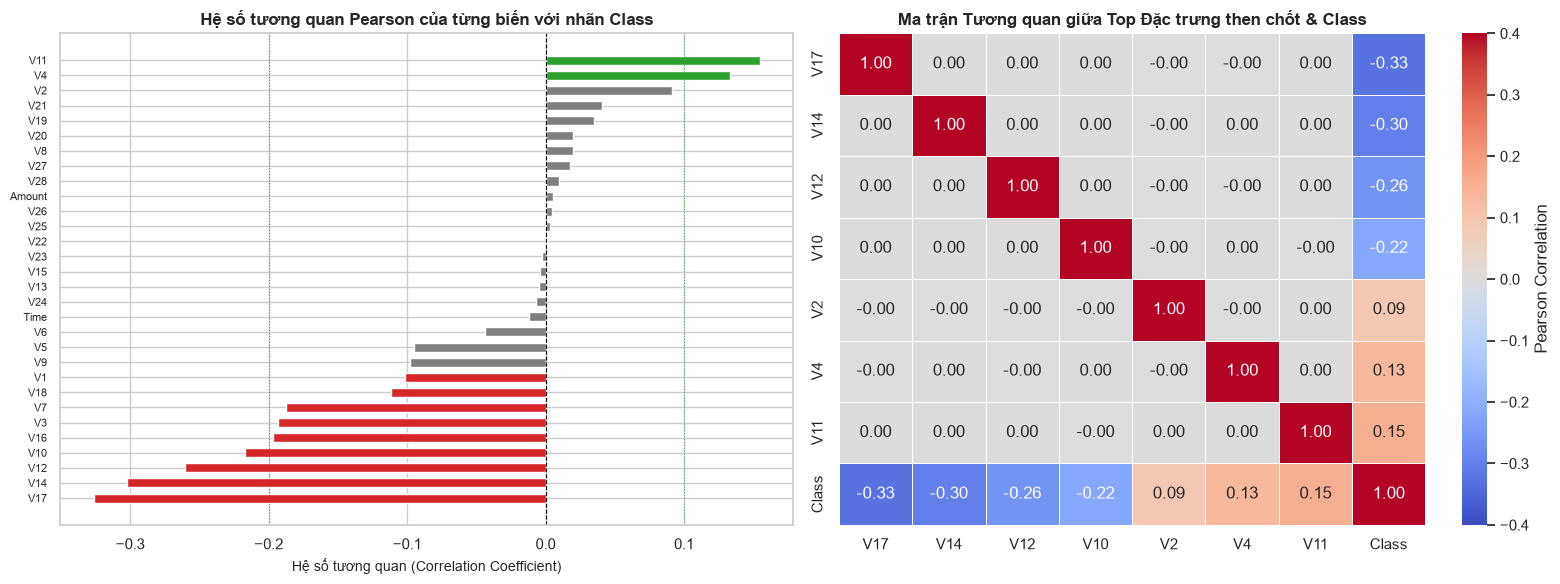

[ĐÃ XUẤT ẢNH] Lưu biểu đồ 3 thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\03_correlation_heatmap.png


In [7]:
# 1. Tính hệ số tương quan Pearson của toàn bộ 30 đặc trưng với nhãn Class
# Loại bỏ nhãn Class và 2 cột phụ trợ trực quan hóa (Hour, log_amount) để giữ đúng 30 đặc trưng gốc
corr_with_class = df.corr()['Class'].drop(['Class', 'Hour', 'log_amount'], errors='ignore').sort_values()
assert len(corr_with_class) == 30, f'Kỳ vọng 30 đặc trưng gốc, nhận được: {len(corr_with_class)}'

print("=" * 60)
print(f"Số đặc trưng gốc được tính tương quan: {len(corr_with_class)} (đã loại Class, Hour, log_amount)")
print("TOP 5 ĐẶC TRƯNG CÓ TƯƠNG QUAN ÂM MẠNH NHẤT VỚI GIAN LẬN:")
print(corr_with_class.head(5).round(4))
print("\nTOP 5 ĐẶC TRƯNG CÓ TƯƠNG QUAN DƯƠNG MẠNH NHẤT VỚI GIAN LẬN:")
print(corr_with_class.tail(5).iloc[::-1].round(4))
print("=" * 60)

# ==============================================================================
# VẼ BIỂU ĐỒ 3: BIỂU ĐỒ TƯƠNG QUAN VÀ HEATMAP (2 SUBPLOTS)
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Barplot tương quan của tất cả các biến với nhãn Class
bar_colors = ['#d62728' if x < -0.1 else ('#2ca02c' if x > 0.1 else '#7f7f7f') for x in corr_with_class.values]
axes[0].barh(range(len(corr_with_class)), corr_with_class.values, color=bar_colors, height=0.6)
axes[0].set_yticks(range(len(corr_with_class)))
axes[0].set_yticklabels(corr_with_class.index, fontsize=8)
axes[0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axes[0].axvline(-0.2, color='#d62728', linewidth=0.8, linestyle=':', alpha=0.7)
axes[0].axvline(0.1, color='#2ca02c', linewidth=0.8, linestyle=':', alpha=0.7)
axes[0].set_title('Hệ số tương quan Pearson của từng biến với nhãn Class', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Hệ số tương quan (Correlation Coefficient)', fontsize=10)

# 2. Heatmap ma trận tương quan giữa Top 8 biến quan trọng nhất và Class
top_corr_features = list(corr_with_class.head(4).index) + list(corr_with_class.tail(3).index) + ['Class']
top_corr_matrix = df[top_corr_features].corr()

sns.heatmap(
    top_corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.4, vmax=0.4,
    linewidths=0.5, cbar_kws={'label': 'Pearson Correlation'}, ax=axes[1]
)
axes[1].set_title('Ma trận Tương quan giữa Top Đặc trưng then chốt & Class', fontsize=12, fontweight='bold')

plt.tight_layout()
fig3_path = FIGURES_DIR / "03_correlation_heatmap.png"
plt.savefig(fig3_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[ĐÃ XUẤT ẢNH] Lưu biểu đồ 3 thành công tại: {fig3_path}")


---
## 6. Phân tích Khả năng Phân tách của Top Đặc trưng then chốt (KDE Density)
* Các biến có tương quan mạnh nhất:
  * **Tương quan âm:** `V14` (-0.30), `V12` (-0.26), `V10` (-0.22), `V17` (-0.33). Khi xảy ra gian lận, giá trị của các biến này bị tụt sâu xuống vùng âm lớn!
  * **Tương quan dương:** `V11` (+0.15), `V4` (+0.13). Khi xảy ra gian lận, giá trị của các biến này tăng vọt lên vùng dương lớn!
* Ta sẽ vẽ đường cong mật độ (Kernel Density Estimation - KDE) để thấy rõ sự tách biệt giữa hai phân phối.


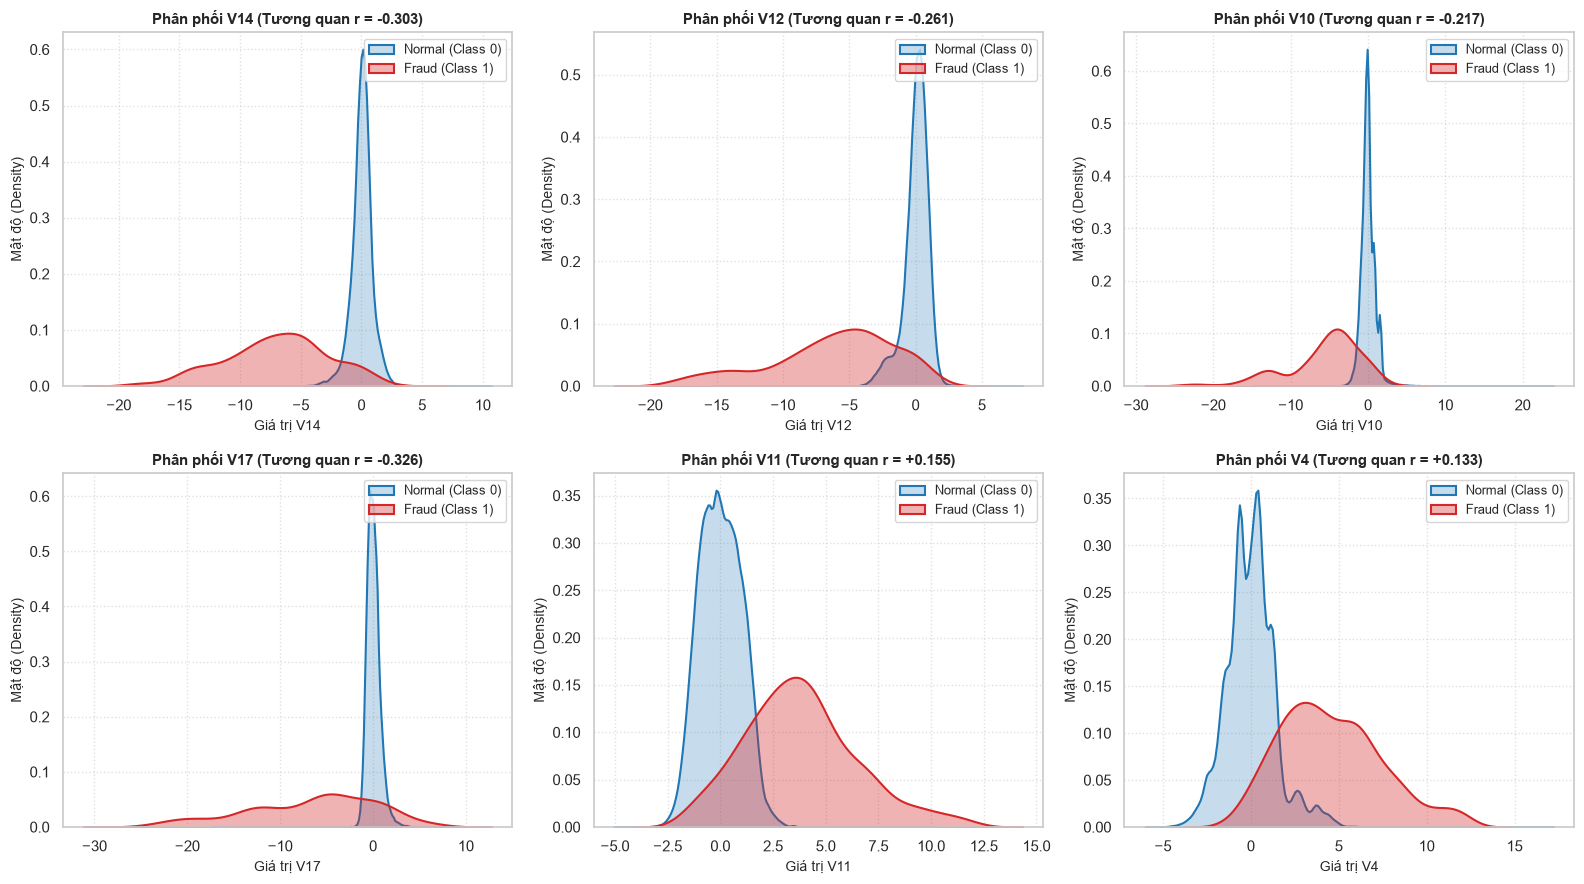

[ĐÃ XUẤT ẢNH] Lưu biểu đồ 4 thành công tại: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\04_kde_top_features.png


In [8]:
# ==============================================================================
# VẼ BIỂU ĐỒ 4: ĐƯỜNG CONG MẬT ĐỘ KDE TRÊN TOP 6 ĐẶC TRƯNG THEN CHỐT
# ==============================================================================
top_features = ['V14', 'V12', 'V10', 'V17', 'V11', 'V4']
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feat in enumerate(top_features):
    ax = axes[idx]
    # Vẽ phân phối của Normal (Xanh)
    sns.kdeplot(
        data=df[df['Class'] == 0][feat], color='#1f77b4',
        label='Normal (Class 0)', fill=True, alpha=0.25, ax=ax, linewidth=1.5
    )
    # Vẽ phân phối của Fraud (Đỏ)
    sns.kdeplot(
        data=df[df['Class'] == 1][feat], color='#d62728',
        label='Fraud (Class 1)', fill=True, alpha=0.35, ax=ax, linewidth=1.5
    )
    corr_val = corr_with_class[feat]
    ax.set_title(f'Phân phối {feat} (Tương quan r = {corr_val:+.3f})', fontsize=11, fontweight='bold')
    ax.set_xlabel(f'Giá trị {feat}', fontsize=10)
    ax.set_ylabel('Mật độ (Density)', fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
fig4_path = FIGURES_DIR / "04_kde_top_features.png"
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"[ĐÃ XUẤT ẢNH] Lưu biểu đồ 4 thành công tại: {fig4_path}")


---
## 7. Kết luận Khoa học & Cơ sở Kỹ thuật bàn giao sang Phase 2

Dựa trên kết quả thực nghiệm khám phá dữ liệu toàn diện ở trên, nhóm rút ra **6 kết luận kỹ thuật bắt buộc** cho đồ án:

1. **Tính toàn vẹn dữ liệu:** Bộ dữ liệu gồm đúng **284.807 giao dịch**, $0$ ô trống (missing = 0), không cần bước xử lý dữ liệu khuyết thiếu.
2. **Quyết định bảo lưu 1.081 dòng trùng lặp:** 
   * Có $1.081$ dòng trùng nhau hoàn toàn, trong đó chứa tới **$19$ giao dịch gian lận**.
   * Nếu tự động xóa các dòng này (`drop_duplicates`), ta sẽ làm mất $3,86\%$ số vụ gian lận hiếm hoi. **Quy tắc: Giữ nguyên $100\%$ các dòng này trong toàn bộ pipeline.**
3. **Mất cân bằng lớp cực đoan (0.173% Fraud):**
   * Tỷ lệ 1 gian lận trên 578 giao dịch bình thường.
   * Cấm sử dụng Accuracy làm thước đo chính. Thước đo trung tâm của đồ án bắt buộc phải là **Recall, Precision, F1-Score và AUPRC (Average Precision)**.
4. **Cơ sở sử dụng RobustScaler:**
   * Thuộc tính `Amount` có độ bất đối xứng rất lớn (Skewness = 16.98, Trung vị = 22.0 USD nhưng Max = 25.691 USD).
   * Không được dùng `StandardScaler` hay `MinMaxScaler` vì sẽ bị bóp méo phân phối bởi các khoản tiền khổng lồ. Bắt buộc dùng **`RobustScaler`** (dựa trên Trung vị và IQR).
   * Thuộc tính `Time` có tính chu kỳ 24h ngày/đêm, cũng được chuẩn hóa qua `RobustScaler`.
   * Các cột `V1–V28` giữ nguyên vì đã qua xử lý PCA tiêu chuẩn của ngân hàng.
5. **Cơ sở phân tách dị biệt của mô hình:**
   * Các thuộc tính `V14, V12, V10, V17` (lệch âm mạnh) và `V11, V4` (lệch dương mạnh) thể hiện sự phân tách mật độ rất rõ rệt giữa Normal và Fraud. Đây sẽ là những đặc trưng chủ lực giúp **Isolation Forest, LOF và One-Class SVM** phát hiện các điểm bất thường.
6. **Chiến lược Zero-Leakage chuyển giao sang Phase 2:**
   * Dữ liệu được chia phân tầng 70/15/15: Train Partition (199.364), Validation (42.721), Test (42.722).
   * Chỉ lấy 199.020 mẫu Normal để fit Scaler và fit 3 mô hình Novelty Detection.
   * Tập Test được niêm phong tuyệt đối cho tới Ngày 12.
